In [ ]:
#mounting google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#importing pandas
import pandas as pd



#loading historical and met object data
df_world = pd.read_csv('/content/drive/MyDrive/ObjectsvsHistory.csv')

df_world.head()


,Historical Incident,Day,Month,Year,Impact,Type of Event,Object.ID,Gallery.Number,AccessionYear,Object.Name,Title,Artist.Display.Name,Object.Begin.Date,City,Country
0,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,Seated Chief (Mwanangana) Playing Sanza,Chokwe artist,1800,NaN,Angola
1,First Presidency of Juan Domin go Perón,4.0,6.0,1946.0,Implementation of social and economic reforms ...,Political,852647,NaN,NaN,NaN,A partir de cero,Enrique Molina,1952,Buenos Aires,Argentina
2,Arrival of the First Fleet,26.0,1.0,1788.0,Marked the beginning of British colonization i...,Colonization,311950,NaN,1978.0,Mask,"Mask (Buk, Krar, or Kara)",NaN,1800,Queensland,Australia
3,"Kingdom of Igodomigodo ""rulers of the sky""",NaN,NaN,1800.0,Period of Warrior Kings that made Benin wealthy,Political,503936,681,1889.0,Eroro,Eroro,NaN,1800,NaN,Benin
4,Tropicália Movement,NaN,4.0,1967.0,Avant garde music and arts movement challengin...,Cultural Change,747797,NaN,NaN,NaN,Nova objetividade brasiliera,Museu de Arte Moderna,1967,Rio de Janeiro,Brazil


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df_world)

https://docs.google.com/spreadsheets/d/1Rq-SVUvw6-ASFJXB2-T2Vm1f-otOR2emADNU2di0BzM/edit#gid=0


In [ ]:
df_world.dtypes

,0
Historical Incident,object
Day,float64
Month,float64
Year,float64
Impact,object
Type of Event,object
Object.ID,int64
Gallery.Number,object
AccessionYear,float64
Object.Name,object


In [ ]:
#loading astrological data
df_astro = pd.read_csv('/content/drive/MyDrive/planetary_transits_1700_present.csv')

df_astro.head()

,Date,Planet,Longitude,Sign,Degree_in_Sign,Is_Retrograde
0,1700-01-01,Sun,281.2248,Capricorn,11.2248,No
1,1700-01-01,Moon,46.9230,Taurus,16.9230,No
2,1700-01-01,Mercury,300.4315,Aquarius,0.4315,No
3,1700-01-01,Venus,293.0180,Capricorn,23.0180,No
4,1700-01-01,Mars,203.8217,Libra,23.8217,No


In [ ]:
df_astro.dtypes

,0
Date,object
Planet,object
Longitude,float64
Sign,object
Degree_in_Sign,float64
Is_Retrograde,object


In [ ]:
#cleaning astro data to combine with met objects_world history data
##turning date column into datetime
import datetime

df_astro.Date = pd.to_datetime(df_astro.Date)


#creating new columns
df_astro['Year'] = df_astro['Date'].dt.year
df_astro['Month'] = df_astro['Date'].dt.month
df_astro['Day'] = df_astro['Date'].dt.day


In [ ]:
df_astro.dtypes

,0
Date,datetime64[ns]
Planet,object
Longitude,float64
Sign,object
Degree_in_Sign,float64
Is_Retrograde,object
Year,int32
Month,int32
Day,int32


In [ ]:
df_astro.head()

,Date,Planet,Longitude,Sign,Degree_in_Sign,Is_Retrograde,Year,Month,Day
0,1700-01-01,Sun,281.2248,Capricorn,11.2248,No,1700,1,1
1,1700-01-01,Moon,46.9230,Taurus,16.9230,No,1700,1,1
2,1700-01-01,Mercury,300.4315,Aquarius,0.4315,No,1700,1,1
3,1700-01-01,Venus,293.0180,Capricorn,23.0180,No,1700,1,1
4,1700-01-01,Mars,203.8217,Libra,23.8217,No,1700,1,1


In [ ]:
#merging dataframes of astro data and world history data
df_merged = pd.merge(df_world, df_astro, on=['Year', 'Month', 'Day'], how='inner')

df_merged.head()

,Historical Incident,Day,Month,Year,Impact,Type of Event,Object.ID,Gallery.Number,AccessionYear,Object.Name,...,Artist.Display.Name,Object.Begin.Date,City,Country,Date,Planet,Longitude,Sign,Degree_in_Sign,Is_Retrograde
0,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,...,Chokwe artist,1800,NaN,Angola,1988-12-22,Sun,270.8712,Capricorn,0.8712,No
1,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,...,Chokwe artist,1800,NaN,Angola,1988-12-22,Moon,81.8420,Gemini,21.8420,No
2,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,...,Chokwe artist,1800,NaN,Angola,1988-12-22,Mercury,282.6452,Capricorn,12.6452,No
3,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,...,Chokwe artist,1800,NaN,Angola,1988-12-22,Venus,245.9275,Sagittarius,5.9275,No
4,Tripartite Accord,22.0,12.0,1988.0,"Cuban military withdrawal, pivotal in ending S...",Military Withdrawal,316173,NaN,1988.0,Figure,...,Chokwe artist,1800,NaN,Angola,1988-12-22,Mars,15.5274,Aries,15.5274,No


In [ ]:
len(df_merged)

1530

In [ ]:
df_merged.columns

Index(['Historical Incident', 'Day', 'Month', 'Year', 'Impact',
       'Type of Event ', 'Object.ID', 'Gallery.Number', 'AccessionYear',
       'Object.Name', 'Title', 'Artist.Display.Name', 'Object.Begin.Date',
       'City', 'Country', 'Date', 'Planet', 'Longitude', 'Sign',
       'Degree_in_Sign', 'Is_Retrograde'],
      dtype='object')

In [ ]:
#viewing entire dataset in Google Sheets to see if I need to do anymore cleaning
sheet = sheets.InteractiveSheet(df=df_merged)

https://docs.google.com/spreadsheets/d/1kEMIZulk5mMQ73JvwkIyonBUepGtggGf8e1HuuUY3v8/edit#gid=0


In [ ]:
#importing modules for visualizations
import seaborn as sns
import matplotlib.pyplot as plt

Text(0.5, 1.0, "Number of Countries in Met Objects 'is Highlights' Category")

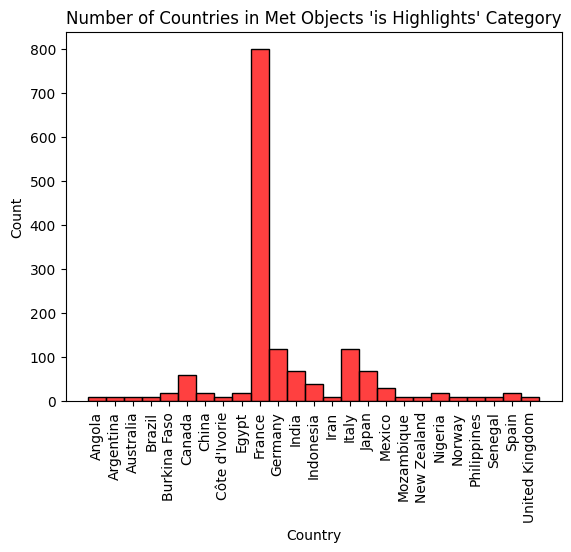

In [ ]:
#Create histogram to explore distributions of countries
df_merged['Country'] = df_merged['Country'].str.strip()
sns.histplot(data=df_merged, x='Country', color="red")
plt.xticks(rotation=90)
plt.title("Number of Countries in Met Objects 'is Highlights' Category")

Text(0.5, 1.0, 'Count of Historical Events From 1700 to 2022')

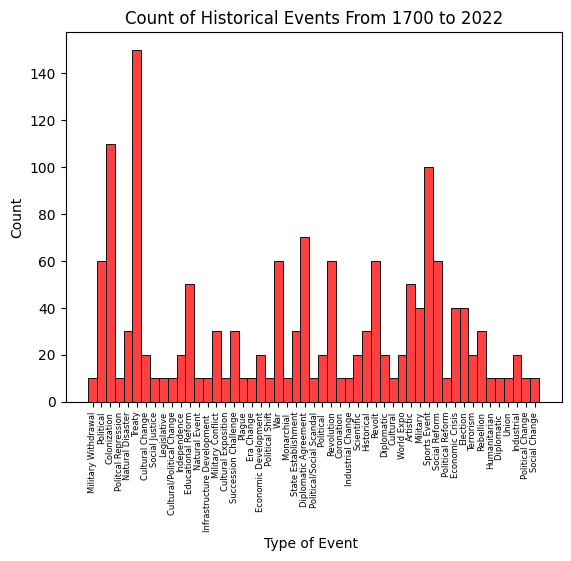

In [ ]:
#create histogram to see distributions of incidents
sns.histplot(data=df_merged, x='Type of Event ', color="red")
plt.xticks(rotation=90, fontsize = 6)
plt.title("Count of Historical Events From 1700 to 2022")


Text(0.5, 1.0, 'Average Year of Historical Events and Average Object Creation Year ')

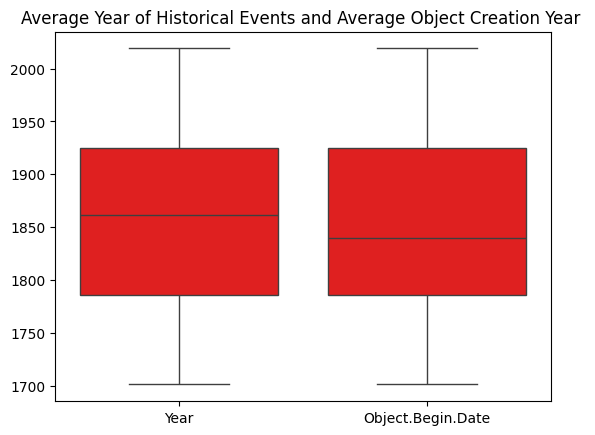

In [ ]:
#create boxplots to examine years
sns.boxplot(data=df_merged[['Year', 'Object.Begin.Date']], color="red")
plt.title("Average Year of Historical Events and Average Object Creation Year ")

Text(0.5, 1.0, 'Astrological Sign Predominant The Year An Object Was Created')

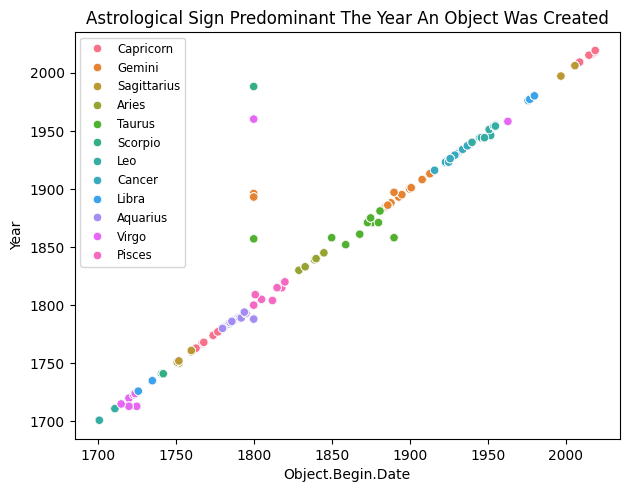

In [ ]:
#scatterplot of object creation date and year of incidents
sns.scatterplot(data=df_merged,x='Object.Begin.Date', y='Year', hue="Sign")
plt.legend(fontsize="small", loc='upper left')
plt.title("Astrological Sign Predominant The Year An Object Was Created")

Text(0.5, 1.0, 'Objects Created vs Type of Historical Event and Year')

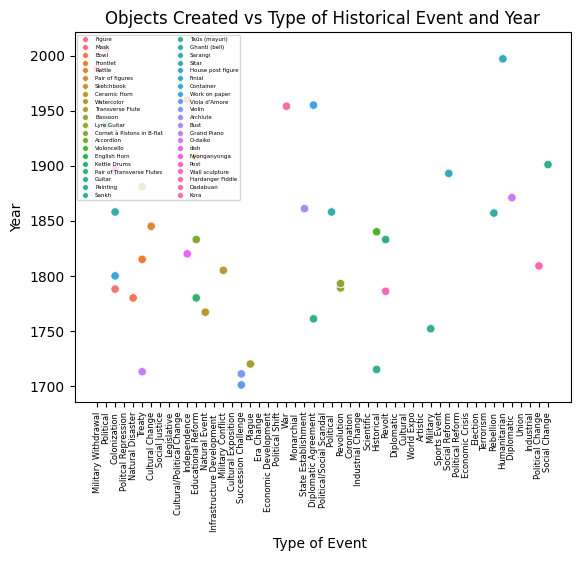

In [ ]:
#scatterplot of historical events and astro data
sns.scatterplot(data=df_merged,x='Type of Event ', y='Year', hue="Object.Name")
plt.legend(ncol=2, loc='upper left', fontsize="4", markerscale=0.7)
plt.xticks(rotation=90, fontsize = 6)
plt.title("Objects Created vs Type of Historical Event and Year")


Text(0.5, 1.0, 'Type of Historical Event by Country')

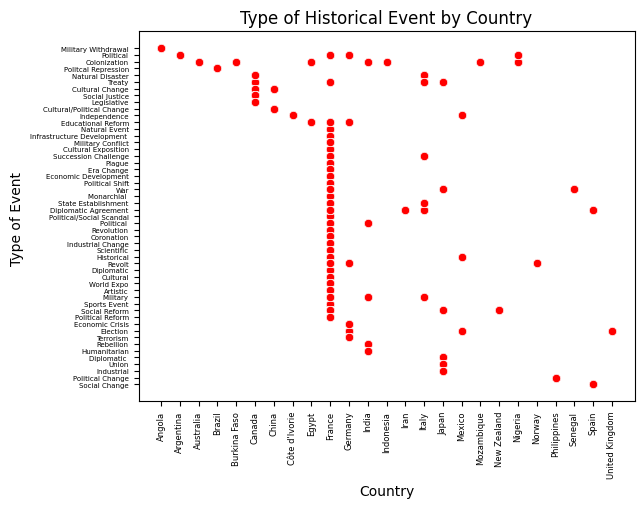

In [ ]:
#scatterplot of cobject creation date and astro data
sns.scatterplot(data=df_merged, x='Country', y='Type of Event ', color="red")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize =5)
plt.title("Type of Historical Event by Country")



Text(0.5, 1.0, 'Country by Objects Created by Sign')

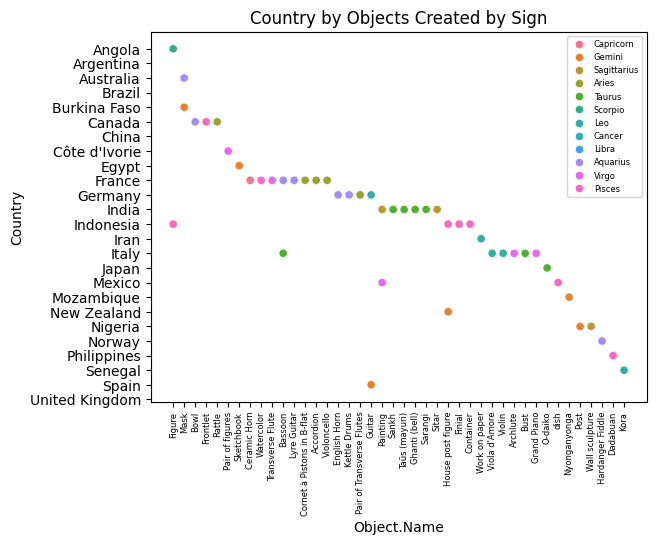

In [ ]:
#scatterplot of object creation date and astro data
sns.scatterplot(data=df_merged,x='Object.Name', y='Country', color="red", hue="Sign")
plt.legend(fontsize=6)
plt.xticks(rotation=90, fontsize = 6,)
plt.title("Country by Objects Created by Sign")




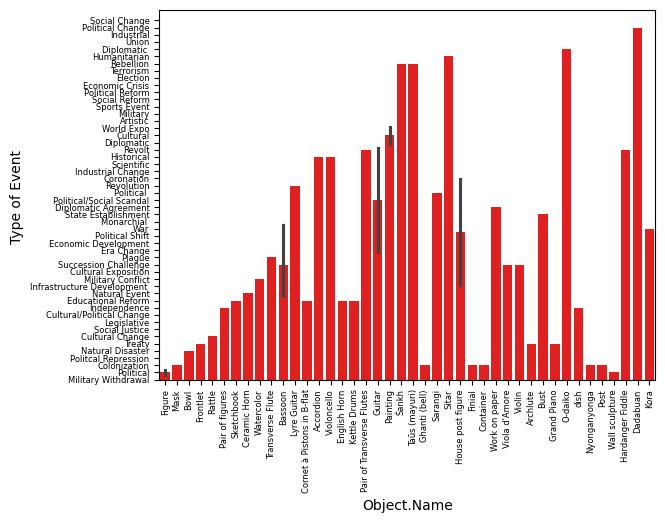

In [ ]:
sns.barplot(data=df_merged,x='Object.Name', y='Type of Event ', color="red")
plt.xticks(rotation=90, fontsize = 6)
plt.yticks(fontsize=6)
plt.gca().invert_yaxis()

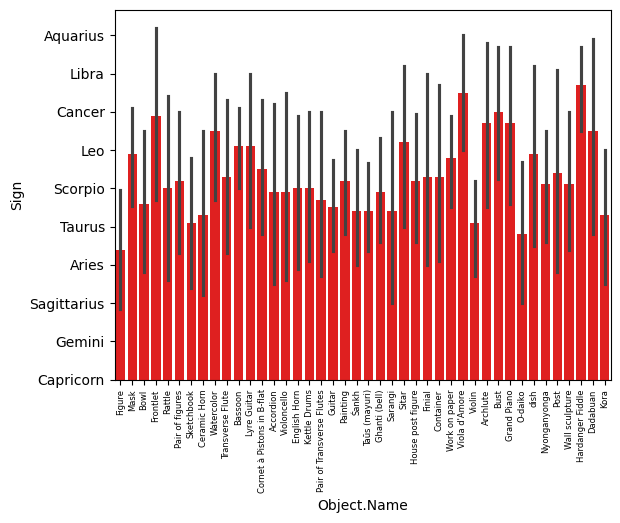

In [ ]:
sns.barplot(data=df_merged,x='Object.Name', y='Sign', color="red")
plt.xticks(rotation=90, fontsize = 6)
plt.gca().invert_yaxis()
